In [2]:
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/Colab Notebooks')

from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuda


In [3]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'MLP'
dataset = 'MNIST'

save_dir = 'content/drive/MyDrive/Colab Notebooks/results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'


In [4]:
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root = 'content/drive/MyDrive/Colab Notebooks/data',
                          train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root = 'content/drive/MyDrive/Colab Notebooks/data',
                         train=False, download=True, transform=transform)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 11.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 353kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.32MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.4MB/s]


In [5]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 100),
                                nn.ReLU(),
                                nn.Linear(100, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [7]:
model = globals()[model_type]().to(DEVICE)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)


Epoch : 1, train loss : 0.308
--------------------
Epoch : 2, train loss : 0.139
--------------------
Epoch : 3, train loss : 0.097
--------------------
Epoch : 4, train loss : 0.074
--------------------
Epoch : 5, train loss : 0.058
--------------------


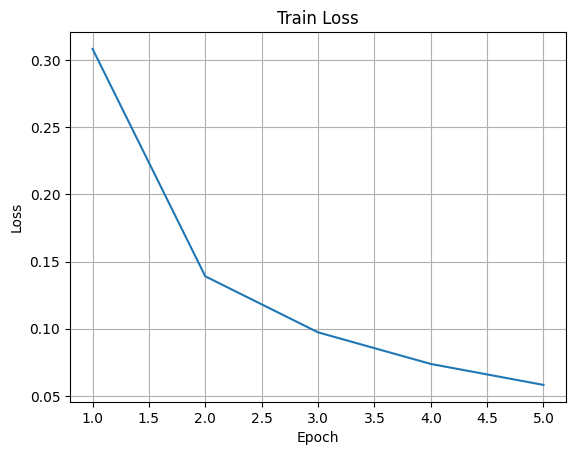

In [8]:
if new_model_train :
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.title('Train Loss')
  plt.grid()

In [9]:
load_model = torch.load(save_model_path,
                        map_location=DEVICE, weights_only=False)

In [10]:
Test(load_model, test_DL)
print(count_params(load_model))

torch.Size([32, 10])
tensor([3, 4, 2, 1, 3, 1, 3, 7, 1, 3, 6, 5, 2, 2, 8, 3, 5, 7, 4, 1, 5, 8, 0, 2,
        5, 5, 0, 3, 7, 3, 3, 8], device='cuda:0')
torch.Size([32, 10])
tensor([7, 6, 9, 0, 7, 5, 9, 0, 0, 9, 3, 9, 5, 1, 1, 6, 2, 4, 9, 5, 0, 6, 3, 3,
        1, 1, 0, 4, 8, 2, 2, 4], device='cuda:0')
torch.Size([32, 10])
tensor([8, 1, 0, 9, 7, 1, 4, 0, 4, 1, 5, 1, 9, 8, 5, 4, 7, 2, 4, 1, 4, 9, 0, 5,
        9, 2, 4, 7, 1, 4, 1, 0], device='cuda:0')
torch.Size([32, 10])
tensor([1, 1, 1, 7, 6, 9, 0, 5, 3, 8, 9, 8, 4, 5, 0, 5, 9, 5, 3, 7, 0, 2, 8, 5,
        9, 1, 7, 9, 2, 6, 0, 7], device='cuda:0')
torch.Size([32, 10])
tensor([9, 5, 0, 5, 2, 1, 5, 2, 6, 2, 4, 1, 3, 0, 2, 2, 9, 2, 1, 6, 4, 1, 5, 9,
        0, 8, 5, 2, 9, 6, 1, 8], device='cuda:0')
torch.Size([32, 10])
tensor([1, 3, 9, 3, 9, 1, 3, 7, 9, 5, 3, 1, 1, 9, 5, 7, 6, 6, 7, 5, 7, 2, 2, 5,
        7, 3, 2, 5, 3, 7, 5, 8], device='cuda:0')
torch.Size([32, 10])
tensor([8, 9, 3, 6, 3, 5, 5, 7, 3, 1, 1, 8, 9, 3, 4, 8, 2, 1, 3, 0, 0, 6,